In [4]:
# 1. Cards & multi deck shoe

import random
import statistics
import matplotlib.pyplot as plt

# Keeping the possible ranks and suits in lists makes it easy to create every card
RANKS = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "Jack", "Queen", "King", "Ace"]
SUITS = ["Hearts", "Diamonds", "Clubs", "Spades"]


class Card:
    """Represents one regular playing card."""

    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    def __str__(self):
        # This controls how a card looks when it is printed
        return f"{self.rank} of {self.suit}"


class Deck:
    """Represents a blackjack shoe that can contain several 52-card decks."""

    def __init__(self, number_of_decks=6):
        self.number_of_decks = number_of_decks
        self.cards = []
        self.needs_shuffle = False
        self.reset()

    def reset(self):
        """Create a fresh shoe, add a cut card, and shuffle everything."""
        self.cards = []
        for _ in range(self.number_of_decks):
            for suit in SUITS:
                for rank in RANKS:
                    self.cards.append(Card(rank, suit))

        # Shuffle real cards first, then put the plastic card in the middle half
        # This leaves enough cards to finish the current round before reshuffling
        self.shuffle()
        cut_position = random.randint(len(self.cards) // 2, 3 * len(self.cards) // 4)
        self.cards.insert(cut_position, "PLASTIC")
        self.needs_shuffle = False

    def shuffle(self):
        random.shuffle(self.cards)

    def draw_card(self):
        """Return one card. Seeing PLASTIC means shuffle before the next round."""
        while True:
            card = self.cards.pop()
            if card == "PLASTIC":
                self.needs_shuffle = True
                # Skip the plastic card; the current round still needs a real card
                continue
            return card


# Quick test for Question 1: 6 decks have 312 cards, plus 1 plastic card
shoe_test = Deck()
print("Cards in a new shoe:", len(shoe_test.cards))
print("Example card drawn:", shoe_test.draw_card())

Cards in a new shoe: 313
Example card drawn: 6 of Spades


In [5]:
# Class skeleton

# outlines for the skeleton
class Hand:
    def __init__(self):
        pass

    def add_card(self, card):
        pass

    def value(self):
        pass


class Player:
    def __init__(self, name, chips=100):
        pass

    def decide(self):
        pass


class BlackjackGame:
    def play_round(self):
        pass

In [6]:
# Completed game classes
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        self.cards.append(card)

    def value(self):
        total = 0
        aces = 0

        for card in self.cards:
            if card.rank in ["Jack", "Queen", "King"]:
                total += 10
            elif card.rank == "Ace":
                total += 11
                aces += 1
            else:
                total += int(card.rank)

        # Each loop changes one ace from 11 to 1, lowering the total by 10
        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total

    def is_bust(self):
        return self.value() > 21

    def __str__(self):
        return ", ".join(str(card) for card in self.cards)


class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()

    def start_round(self):
        # A new round always begins with an empty hand
        self.hand = Hand()

    def decide(self):
        # Regular computer players use the dealer rule in this lab
        return self.hand.value() < 17


class Dealer(Player):
    def decide(self):
        return self.hand.value() < 17


class HumanPlayer(Player):
    def decide(self):
        answer = input(f"{self.name}, your hand is {self.hand.value()}. Hit or stay? ").lower()
        return answer.startswith("h")


def hi_lo_value(card):
    """Return the Hi-Lo count value requested in Question 6."""
    if card.rank in ["2", "3", "4", "5", "6"]:
        return 1
    if card.rank in ["7", "8", "9"]:
        return 0
    return -1


class CountingPlayer(Player):
    def __init__(self, name, chips=100, threshold=0):
        super().__init__(name, chips)
        self.threshold = threshold
        self.running_count = 0

    def observe(self, card):
        # This is called whenever the player can see a card on the table
        self.running_count += hi_lo_value(card)

    def reset_count(self):
        self.running_count = 0

    def decide(self):
        # Negative count: hit. Count at or above the threshold: stay
        return self.running_count < self.threshold and self.hand.value() < 21


class BlackjackGame:
    def __init__(self, dealer, players, number_of_decks=6, verbose=True):
        self.dealer = dealer
        self.players = players
        self.shoe = Deck(number_of_decks)
        self.verbose = verbose

    def counting_players(self):
        return [player for player in self.players if isinstance(player, CountingPlayer)]

    def deal_to(self, person, visible=True):
        """Deal one card and update counters only if the card is visible."""
        card = self.shoe.draw_card()
        person.hand.add_card(card)

        if visible:
            for counter in self.counting_players():
                counter.observe(card)
        return card

    def start_round(self):
        # If the plastic was dealt during the last round, start this one with a new shoe
        if self.shoe.needs_shuffle:
            self.shoe.reset()
            for counter in self.counting_players():
                counter.reset_count()

        self.dealer.start_round()
        active_players = [player for player in self.players if player.chips > 0]
        for player in active_players:
            player.start_round()

        # All player cards are shown, only the dealer's second card begins hidden
        for player in active_players:
            self.deal_to(player, visible=True)
        self.deal_to(self.dealer, visible=True)
        for player in active_players:
            self.deal_to(player, visible=True)
        self.deal_to(self.dealer, visible=False)

        return active_players

    def play_round(self):
        active_players = self.start_round()
        if not active_players:
            return

        # Each player takes turns before the dealer
        for player in active_players:
            while player.decide() and not player.hand.is_bust():
                self.deal_to(player, visible=True)

        # dealer's hidden card is now revealed, so it can be counted
        for counter in self.counting_players():
            counter.observe(self.dealer.hand.cards[1])

        while self.dealer.decide() and not self.dealer.hand.is_bust():
            self.deal_to(self.dealer, visible=True)

        dealer_total = self.dealer.hand.value()
        for player in active_players:
            player_total = player.hand.value()

            # Every player effectively wagers one chip per round
            if player.hand.is_bust():
                player.chips -= 1
            elif self.dealer.hand.is_bust() or player_total > dealer_total:
                player.chips += 1
            elif player_total < dealer_total:
                player.chips -= 1
            # A tie is a push, so chips do not change

        if self.verbose:
            print(f"Dealer: {self.dealer.hand} ({dealer_total})")
            for player in active_players:
                print(f"{player.name}: {player.hand} ({player.hand.value()}) | chips: {player.chips}")
            print()

    def play_game(self, rounds=50, stop_player=None):
        """Play several rounds, stopping early if the selected player runs out of chips."""
        for _ in range(rounds):
            if stop_player is not None and stop_player.chips <= 0:
                break
            self.play_round()

In [7]:
# Testing the game

random.seed(7)  # A seed makes this demonstration repeatable.
dealer = Dealer("Dealer")
basic_players = [Player("Player 1"), Player("Player 2"), Player("Player 3")]
test_game = BlackjackGame(dealer, basic_players, verbose=True)
test_game.play_game(rounds=3)

Dealer: King of Diamonds, 7 of Clubs (17)
Player 1: Jack of Hearts, King of Clubs (20) | chips: 101
Player 2: Ace of Diamonds, 3 of Diamonds, Ace of Clubs, 5 of Clubs (20) | chips: 101
Player 3: 9 of Spades, Jack of Spades (19) | chips: 101

Dealer: 7 of Spades, 8 of Diamonds, 6 of Clubs (21)
Player 1: Ace of Spades, 3 of Diamonds, 9 of Spades, Jack of Diamonds (23) | chips: 100
Player 2: 7 of Hearts, 8 of Hearts, Jack of Hearts (25) | chips: 100
Player 3: 8 of Diamonds, Jack of Clubs (18) | chips: 100

Dealer: 7 of Clubs, Queen of Diamonds (17)
Player 1: 5 of Clubs, 10 of Spades, 5 of Diamonds (20) | chips: 101
Player 2: King of Hearts, Ace of Diamonds (21) | chips: 101
Player 3: Queen of Hearts, Jack of Hearts (20) | chips: 101



In [9]:
#50 round test

def run_one_game(threshold=0, rounds=50, verbose=False, player_class=CountingPlayer):
    """Run one game and return the strategy player's ending chip total."""
    dealer = Dealer("Dealer")
    strategy_player = player_class("Counting Player", chips=100, threshold=threshold)
    other_players = [Player("Computer 1"), Player("Computer 2"), Player("Computer 3")]

    game = BlackjackGame(dealer, [strategy_player] + other_players, verbose=verbose)
    game.play_game(rounds=rounds, stop_player=strategy_player)
    return strategy_player.chips


random.seed(12)
starting_chips = 100
final_chips = run_one_game(threshold=0, rounds=50, verbose=False)
winnings = final_chips - starting_chips
print(f"Final chips: {final_chips}")
print(f"Strategy player's winnings after 50 rounds: {winnings}")

Final chips: 73
Strategy player's winnings after 50 rounds: -27


Average winnings per round: -0.399
Standard deviation after 50 rounds: 6.62
Probability of net winning: 0.0%
Probability of net losing: 100.0%


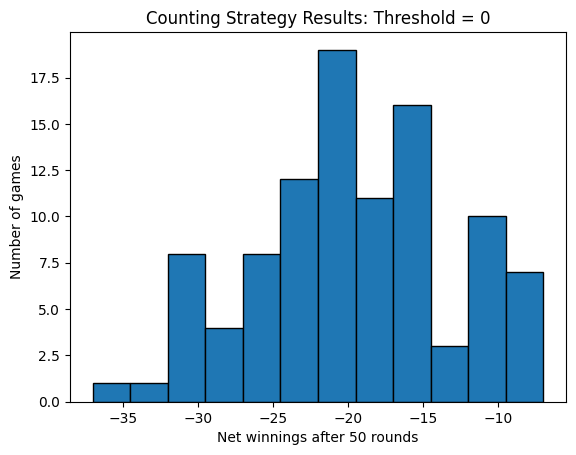

In [10]:
# running 100 games

random.seed(25)
results = []

for _ in range(100):
    # Store final chips
    results.append(run_one_game(threshold=0, rounds=50, verbose=False))

winnings_list = [chips - starting_chips for chips in results]
average_winnings_per_round = statistics.mean(winnings_list) / 50
standard_deviation = statistics.pstdev(winnings_list)
probability_winning = sum(value > 0 for value in winnings_list) / len(winnings_list)
probability_losing = sum(value < 0 for value in winnings_list) / len(winnings_list)

print(f"Average winnings per round: {average_winnings_per_round:.3f}")
print(f"Standard deviation after 50 rounds: {standard_deviation:.2f}")
print(f"Probability of net winning: {probability_winning:.1%}")
print(f"Probability of net losing: {probability_losing:.1%}")

plt.hist(winnings_list, bins=12, edgecolor="black")
plt.xlabel("Net winnings after 50 rounds")
plt.ylabel("Number of games")
plt.title("Counting Strategy Results: Threshold = 0")
plt.show()

In [11]:
# comparing 5 threshold values

random.seed(40)
thresholds = [-3, -2, -1, 0, 1, 2]
threshold_results = {}

for threshold in thresholds:
    ending_chips = [run_one_game(threshold=threshold, rounds=50) for _ in range(100)]
    net_winnings = [chips - starting_chips for chips in ending_chips]
    threshold_results[threshold] = statistics.mean(net_winnings) / 50

print("Threshold comparison")
for threshold, average in threshold_results.items():
    print(f"Threshold {threshold:>2}: average winnings per round = {average:.3f}")

best_threshold = max(threshold_results, key=threshold_results.get)
print(f"\nBest threshold in this test: {best_threshold}")

Threshold comparison
Threshold -3: average winnings per round = -0.295
Threshold -2: average winnings per round = -0.304
Threshold -1: average winnings per round = -0.340
Threshold  0: average winnings per round = -0.386
Threshold  1: average winnings per round = -0.424
Threshold  2: average winnings per round = -0.465

Best threshold in this test: -3


In [12]:
# new strategy

class HybridCountingPlayer(CountingPlayer):
    def decide(self):
        total = self.hand.value()

        # These two rules are based on the hand value, not the count
        if total <= 11:
            return True
        if total >= 17:
            return False

        # For the middle totals, using same count idea from Question 6
        return self.running_count < self.threshold


def average_winnings_for(player_class, threshold=0, games=100):
    ending_chips = [run_one_game(threshold=threshold, rounds=50, player_class=player_class)
                    for _ in range(games)]
    return statistics.mean([chips - starting_chips for chips in ending_chips])


random.seed(65)
original_average = average_winnings_for(CountingPlayer, threshold=0)
random.seed(65)
hybrid_average = average_winnings_for(HybridCountingPlayer, threshold=0)

print(f"Original count-only strategy average winnings: {original_average:.2f}")
print(f"Hybrid strategy average winnings: {hybrid_average:.2f}")

if hybrid_average > original_average:
    print("The hybrid strategy increased average winnings in this simulation.")
else:
    print("The hybrid strategy decreased average winnings in this simulation.")

Original count-only strategy average winnings: -20.70
Hybrid strategy average winnings: -4.95
The hybrid strategy increased average winnings in this simulation.
